#1.  **Filtragem Colaborativa (baseada em usuário)**

**O código implementa um User-Based Collaborative Filtering:**

Essa abordagem funciona da seguinte forma no código:

Comportamento e perfil de pares: Recomendação de uma carteira de investimentos com base nas escolhas e na experiência de outros usuários parecidos.   
Cálculo de Similaridade: Utiliza métricas como Distância Euclidiana e Similaridade de Cosseno para comparar os vetores de alocação entre investidores.   
Encontrar Vizinhos Próximos (KNN): O algoritmo NearestNeighbors identifica quais são os investidores com comportamento/alocação mais parecidos para compor a recomendação.   


## **Importando as biblioteca**s

In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## **Construindo a base de dados**

In [ ]:
import pandas as pd
import numpy as np

# Definir semente aleatória para reprodutibilidade
np.random.seed(42)

# Parâmetros
n_investidores = 50

# 1. Gerar dados principais
ids = [f"INV_{i+1:03d}" for i in range(n_investidores)]
valor_total = np.round(np.random.uniform(5000, 500000, size=n_investidores), 2)
tempo_meses = np.random.randint(1, 120, size=n_investidores)

# 2. Gerar a coluna 'Perfil_do_investidor'
perfis_opcoes = ['Conservador', 'Moderado', 'Sofisticado']
perfil_investidor = np.random.choice(perfis_opcoes, size=n_investidores, p=[0.5, 0.3, 0.2])

# 3. Gerar alocação de ativos (soma = 100% por investidor)
# Colunas: Renda Fixa, Ações, Imóveis, Criptomoedas, Fundos Multimercado
alocacao_bruta = np.random.dirichlet(alpha=[2, 1, 1, 0.5, 1], size=n_investidores) * 100
alocacao_pct = np.round(alocacao_bruta, 2)

# 4. Construir o DataFrame com todas as colunas requisitadas
df_investidores = pd.DataFrame({
    'id_investidor': ids,
    'Valor_total_investido': valor_total,
    'tempo_total_de_investimentos': tempo_meses,
    'Perfil_do_investidor': perfil_investidor,
    'pct_Renda_Fixa': alocacao_pct[:, 0],
    'pct_Acoes': alocacao_pct[:, 1],
    'pct_Imoveis': alocacao_pct[:, 2],
    'pct_Criptomoedas': alocacao_pct[:, 3],
    'pct_Multimercado': alocacao_pct[:, 4]
})



--- DataFrame Completo (Primeiras 10 linhas) ---
  id_investidor  Valor_total_investido  tempo_total_de_investimentos  \
0       INV_001              190397.36                            63   
1       INV_002              475603.58                            18   
2       INV_003              367337.00                            90   
3       INV_004              301335.95                            44   
4       INV_005               82229.23                            34   
5       INV_006               82217.29                            74   
6       INV_007               33751.39                            62   
7       INV_008              433757.19                           100   
8       INV_009              302551.93                            14   
9       INV_010              355495.93                            95   

  Perfil_do_investidor  pct_Renda_Fixa  pct_Acoes  pct_Imoveis  \
0          Sofisticado           27.01      23.06        41.00   
1             Moderado    

In [ ]:
print("--- DataFrame ---")
print(df_investidores.head(10))

--- DataFrame ---
  id_investidor  Valor_total_investido  tempo_total_de_investimentos  \
0       INV_001              190397.36                            63   
1       INV_002              475603.58                            18   
2       INV_003              367337.00                            90   
3       INV_004              301335.95                            44   
4       INV_005               82229.23                            34   
5       INV_006               82217.29                            74   
6       INV_007               33751.39                            62   
7       INV_008              433757.19                           100   
8       INV_009              302551.93                            14   
9       INV_010              355495.93                            95   

  Perfil_do_investidor  pct_Renda_Fixa  pct_Acoes  pct_Imoveis  \
0          Sofisticado           27.01      23.06        41.00   
1             Moderado           40.29      30.07        

## **Features**

In [ ]:
df_investidores.columns

Index(['id_investidor', 'Valor_total_investido',
       'tempo_total_de_investimentos', 'Perfil_do_investidor',
       'pct_Renda_Fixa', 'pct_Acoes', 'pct_Imoveis', 'pct_Criptomoedas',
       'pct_Multimercado'],
      dtype='object')

In [ ]:
features =df_investidores[['Valor_total_investido',
       'tempo_total_de_investimentos',
       'pct_Renda_Fixa', 'pct_Acoes', 'pct_Imoveis', 'pct_Criptomoedas',
       'pct_Multimercado']]

## **Pré-processamento**

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

## **Métrica WCSS (Within-Cluster Sum of Squares)**

O WCSS mede a variabilidade interna de cada cluster. Ele é calculado somando as distâncias quadráticas de cada ponto até o centróide do cluster ao qual pertence.


### **O que o WCSS representa**
* **Coesão interna**: Quanto menor o WCSS, mais compactos e homogêneos são os clusters. Os pontos estão próximos de seus centróides.

* **Dispersão**: Quanto maior o WCSS, mais espalhados os pontos estão dentro de cada cluster, indicando uma má clusterização.

In [ ]:
wccc=[]
k_reange =range(1,20)
for k in k_reange:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(scaled_features)
    wccc.append(kmeans.inertia_)

## **Método do Cotovelo (Elbow Method)**

O uso mais comum do WCSS na prática é determinar o número ideal de clusters** (K)**. O procedimento é:

* Rodar o **K-Means** para diferentes valores de **K (ex: 1 a 10)**.

* Calcular o** WCSS **final para cada **K**.

* Plotar um gráfico de **K vs. WCSS**.

O gráfico típico mostra uma curva decrescente. O cotovelo (ponto onde a queda do WCSS **desacelera bruscamente**) indica o K mais adequado. Antes do cotovelo, adicionar clusters reduz muito o WCSS; depois, o ganho é margina


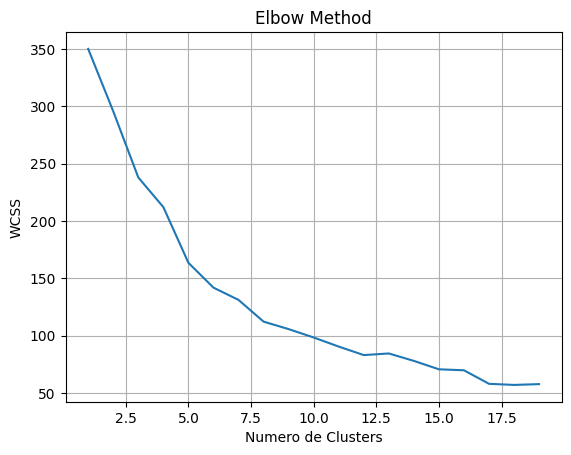

In [ ]:
import matplotlib.pyplot as plt
plt.plot(k_reange,wccc)
plt.xlabel("Numero de Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid()
plt.show()


## **Definindo o algoritmo KMeans**





In [ ]:
k_means = KMeans(n_clusters=5, random_state=85)


In [ ]:
k_means.fit(scaled_features)

KMeans(n_clusters=5, random_state=85)

In [ ]:
df_investidores_cluster = df_investidores.copy()

In [ ]:
df_investidores_cluster

In [ ]:
df_investidores_cluster['cluster'] =k_means.predict(scaled_features)

In [ ]:
df_investidores_cluster['cluster'].head(10)

,cluster
0,0
1,1
2,3
3,1
4,0
5,0
6,0
7,1
8,0
9,3


In [ ]:
centroides =pd.DataFrame(scaler.inverse_transform(k_means.cluster_centers_),columns=features.columns)

In [ ]:
centroides['cluster'] =centroides.index

In [ ]:
centroides

,Valor_total_investido,tempo_total_de_investimentos,pct_Renda_Fixa,pct_Acoes,pct_Imoveis,pct_Criptomoedas,pct_Multimercado,cluster
0,102829.955714,53.642857,27.410000,12.690714,38.488571,9.312857,12.095714,0
1,349764.183750,60.500000,48.374375,19.435625,14.785625,6.167500,11.237500,1
2,228259.746667,65.000000,16.223333,9.016667,2.036667,64.103333,8.620000,2
3,237549.038750,86.000000,24.736250,41.023750,16.267500,9.978750,7.990000,3
4,185066.528889,29.444444,25.602222,13.885556,10.147778,7.288889,43.076667,4
